## Assignment 10: PID Controllers


<div class="alert alert-light">

  **Name:** Simon Schneider, Suleman Ali Khan, Adriano Saurwein
  
  **Matriculation Number:** 23-919-863, 21-715-917, 23-981-574
  
</div>



The submission deadline is <span style="background-color:rgba(0, 150, 255, 0.5); padding:2px 4px; border-radius:3px;">Monday, 2026-Nov-30 (23:59)</span>.
Students <span style="background-color:rgba(70, 141, 9, 0.5); padding:2px 4px; border-radius:3px;">can work in teams of three</span> and provide their results together. 

Fill in your responses below in the marked blocks. The expected length of each answer is provided in each block.

- (S) Short, 1–2 sentences (~20–40 words). *A quick factual or definition-style answer.*
- (M) Medium, 3–8 sentences (~60–120 words). *Brief explanation with reasoning or an example.*
- (L) Long, multi-paragraph (150–300 words). *Detailed discussion, include reasoning, examples, and context.*
- (V) Visualizations and graphs. *Include plots or figures that illustrate your results.*
- (E) Statistical evaluation and information. *Provide numeric context such as mean, variance, random seed used, confidence intervals, etc.*

Save this notebook and upload the modified file to Moodle.

The motivation for this assignment is to learn about the change of performance when dynamically adapting the modulation and coding scheme (phymode), and to a lesser extent, the transmission power, in a wireless network. An algorithm is required to be used by the MAC Layer Management Entity (MLME) of IEEE 802.11 stations, with the objective to achieve efficient radio channel (radio spectrum) usage. This so-called radio resource management algorithm must in this assignment be realized by use of a Proportional-Integral-Derivative (PID) controller as introduced in the class. The objective of the algorithm is to improve performance (throughput, delay etc.) at minimum transmission power.

---

## Questions



### Step 1: PID Basics (2 points)

1) Research into the concept of PIDs, e.g. through background reading [PID Without a PhD](https://gitlab.ethz.ch/wireless/BackgroundReading/-/tree/main/Algorithms%20and%20Game%20Theory/PID%20Controller). Why is it important to fine-tune PID controller gains to prevent oscillations in the system response?

<div class="alert alert-info">

(S) Answer: Poorly tuned gains can make the controller overreact or accumulate too much error, causing overshoot and repeated corrections. This creates oscillations, slows settling, and can destabilize the system; careful tuning balances responsiveness with damping.

</div>

2) Open the notebook [`PID_Controller.ipynb`](../../notebooks/04%20Mobile%20Computing/PID_Controller.ipynb). Set $\text{in\_values}=\text{array1}$ and $\text{Kp}=\text{Ki}=\text{Kd}=1$. Provide the series P(t) and explain why it behaves this way.

<div class="alert alert-info">

(S) Answer: With `in_values=array1` and all gains set to 1, the series is P(t) = [3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 2, 1, 0, -1, -2, -2, -2, -2, -2, -2, -2, -1, 0, 1, 2, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3]. It equals the current error (setpoint 3 minus input), so it falls as the input rises and returns to 3 when the input returns to zero.

</div>

3) Provide the series I(t) and explain why it behaves this way.

<div class="alert alert-info">

(S) Answer: I(t) = [0, 3, 6, 9, 12, 15, 18, 21, 24, 27, 30, 32, 33, 33, 32, 30, 28, 26, 24, 22, 20, 18, 17, 17, 18, 20, 23, 26, 29, 32, 35, 38, 41, 44, 47, 50]. It accumulates past errors: it rises while the error is positive, falls while the error is negative, then rises again. The first value is 0 because the notebook initializes the accumulator at zero and begins summing from the second sample.

</div>

4) Provide the series D(t) and explain why it behaves this way.

<div class="alert alert-info">

(S) Answer: D(t) = [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, -1, -1, -1, -1, -1, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0]. It is the change in error between adjacent samples, so it is zero on flat sections and produces short negative or positive pulses as the input rises or falls.

</div>

5) Update the input as $\text{in\_values}=\text{array2}$ and $\text{Kp}=\text{Ki}=\text{Kd}=2$. Provide the visualized PID output. What signal influences the output the most and why?

<div class="alert alert-info">

(V, M) Answer: With `in_values=array2` and all gains set to 2, the plotted output is the sum of P(t), I(t), and D(t). The integral term has the largest sustained influence (maximum absolute value 54, versus 26 for P and 20 for D) because it accumulates error over time; D instead produces brief spikes at abrupt changes. The sharp transient at t=31 reaches an output of 76.

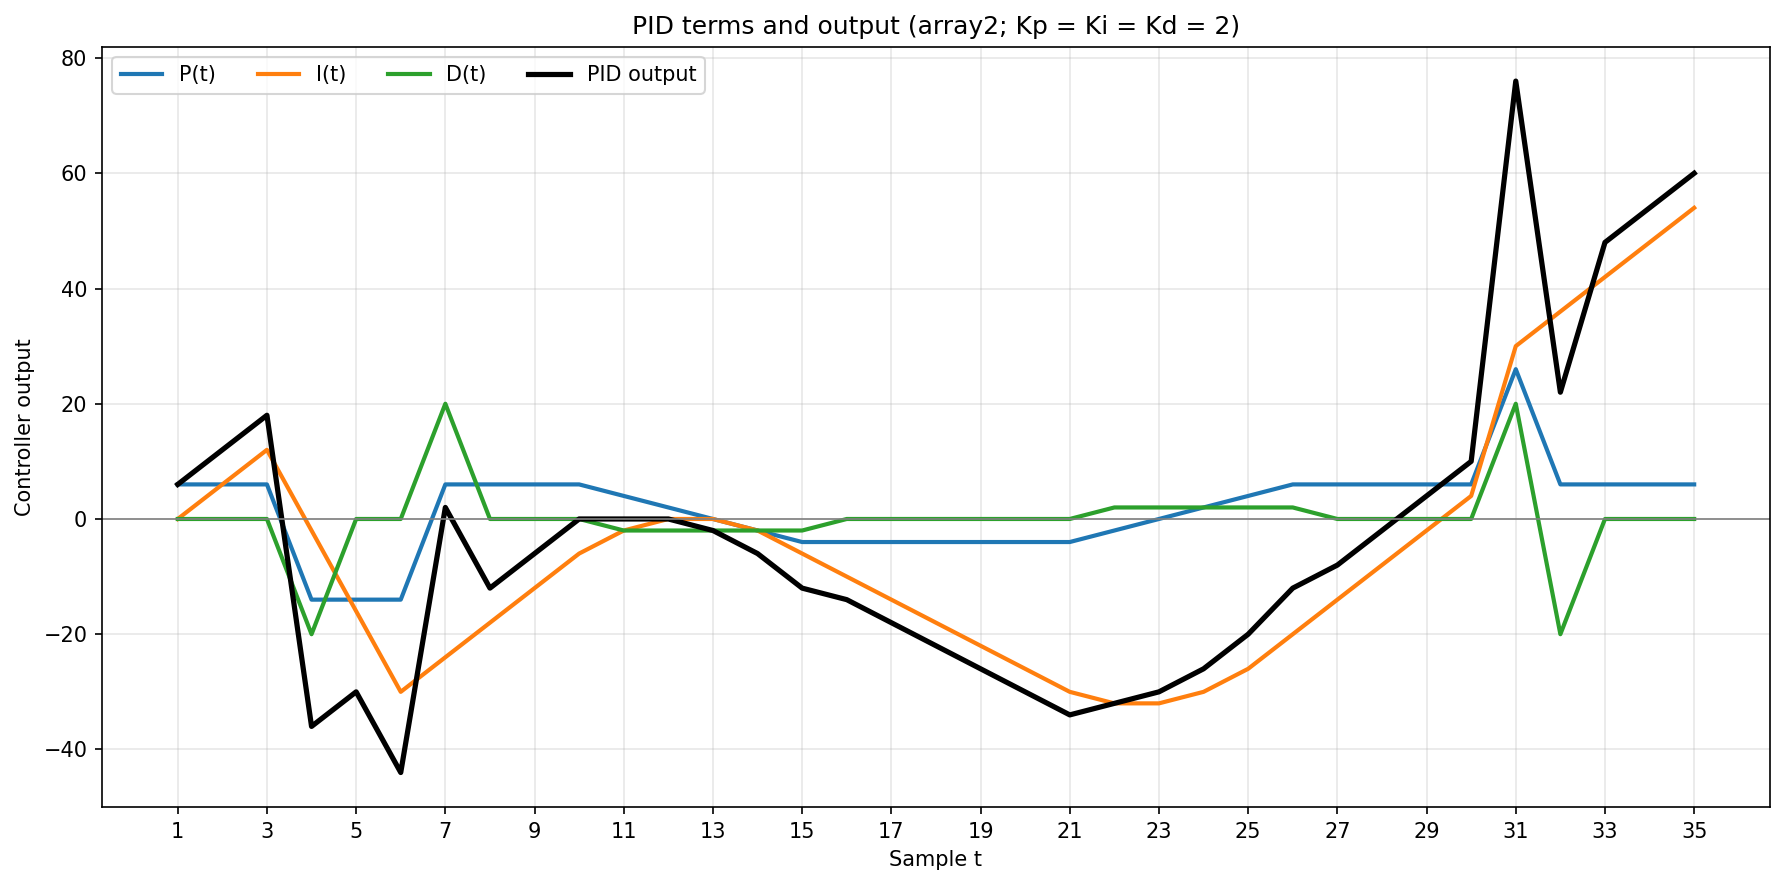

</div>

6) Provide the animated gif of the PID controller. Analyze how the weights affect the controller state.

<div class="alert alert-info">

(V, M) Answer: 

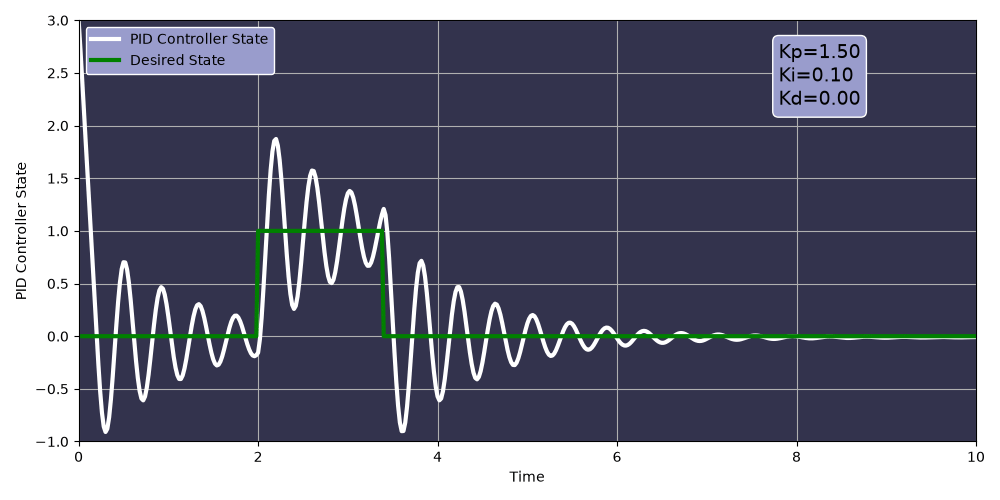

In the animation, Ki stays at 0.1, Kp decreases from 1.5 to 1.0, and Kd increases from 0 to about 0.03. Lower Kp makes the response to current error less aggressive, while increasing Kd adds damping against rapid changes; Ki continues correcting accumulated error. The process state `p_response` is global and is not reset between simulated frames, so some frame-to-frame change also carries over from the previous simulation.

</div>

### Step 2: Scenario Preparation (3 points)
1) Open [`Jemula802_Run.ipynb`](../../notebooks/01%20Jemula/Jemula802_Run.ipynb). Input the scenario `"./jemula-project/my-simulations/scenarios/ETH_Course/WNMC_Moving_Stations.xml"` and enter your legi number. One station is moving between 0m and 500m back and forth. Familiarize yourself with the scenario. How many stations are there in total?

<div class="alert alert-info">

(S) Answer: There are 2 stations in total: station 1 is stationary and station 2 moves back and forth (0 - 500 m)

2) Familiarize yourself again with the concept of a queue. What role does it play in the IEEE 802.11 protocol?

<div class="alert alert-info">

(S) Answer: A queue buffers packets waiting for transmission. In IEEE 802.11, it holds them while the station waits for channel access; if it fills up, packets are dropped.

3) What is the maximum queue size of the Backoff Entity in our scenario?

<div class="alert alert-info">

(S) Answer: The maximum queue size is 100 packets

4) Locate the field `NameOfAlgorithm`that is not set to "None". Find the corresponding algorithm in `"jemula-project/my-simulations/algorithms/layer2_802Algorithms"` and familiarize yourself with the file. Which two physical properties can you set?

<div class="alert alert-info">

(S) Answer: PHY mode and Transmission power.

5) Run the scenario. A new PID controller screen shows up, coming from the plot-function in the algorithm. Provide a screenshot and explain what is shown.

<div class="alert alert-info">

(V, S) Answer: 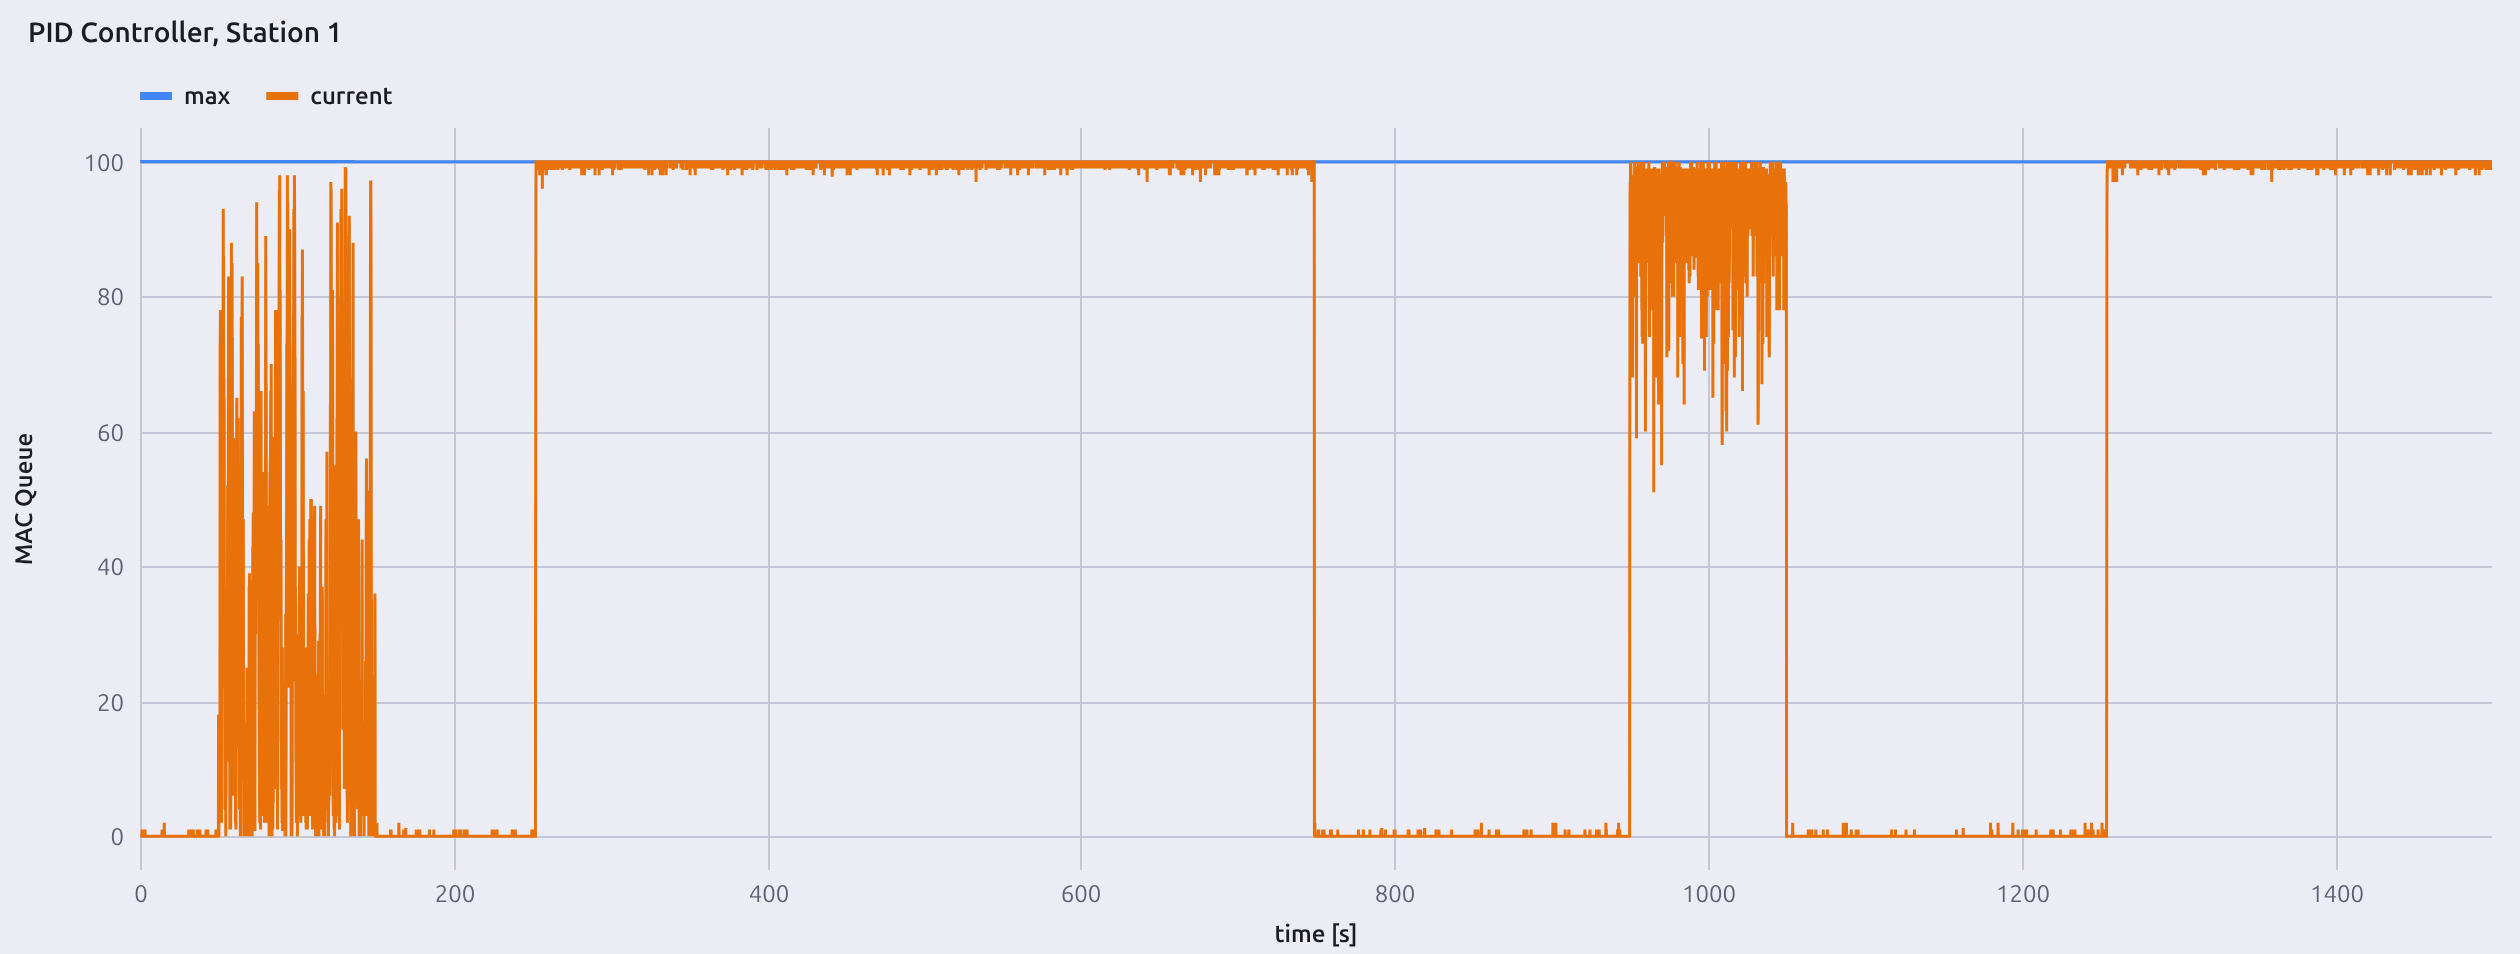

The plot shows Station 1’s queue occupancy over time: blue is the maximum of 100 packets, and orange is the current occupancy. The queue fills when traffic exceeds transmission capacity and drains when the link can keep up; a full queue causes packet drops.

6) Open [`Jemula802_Results.ipynb`](../../notebooks/01%20Jemula/Jemula802_Results.ipynb) and input the same scenario path. Use the total logged outputs for throughput and offer, but leave delay as it is. Provide the graph of offer and throughput over time.

<div class="alert alert-info">

(V) Answer: 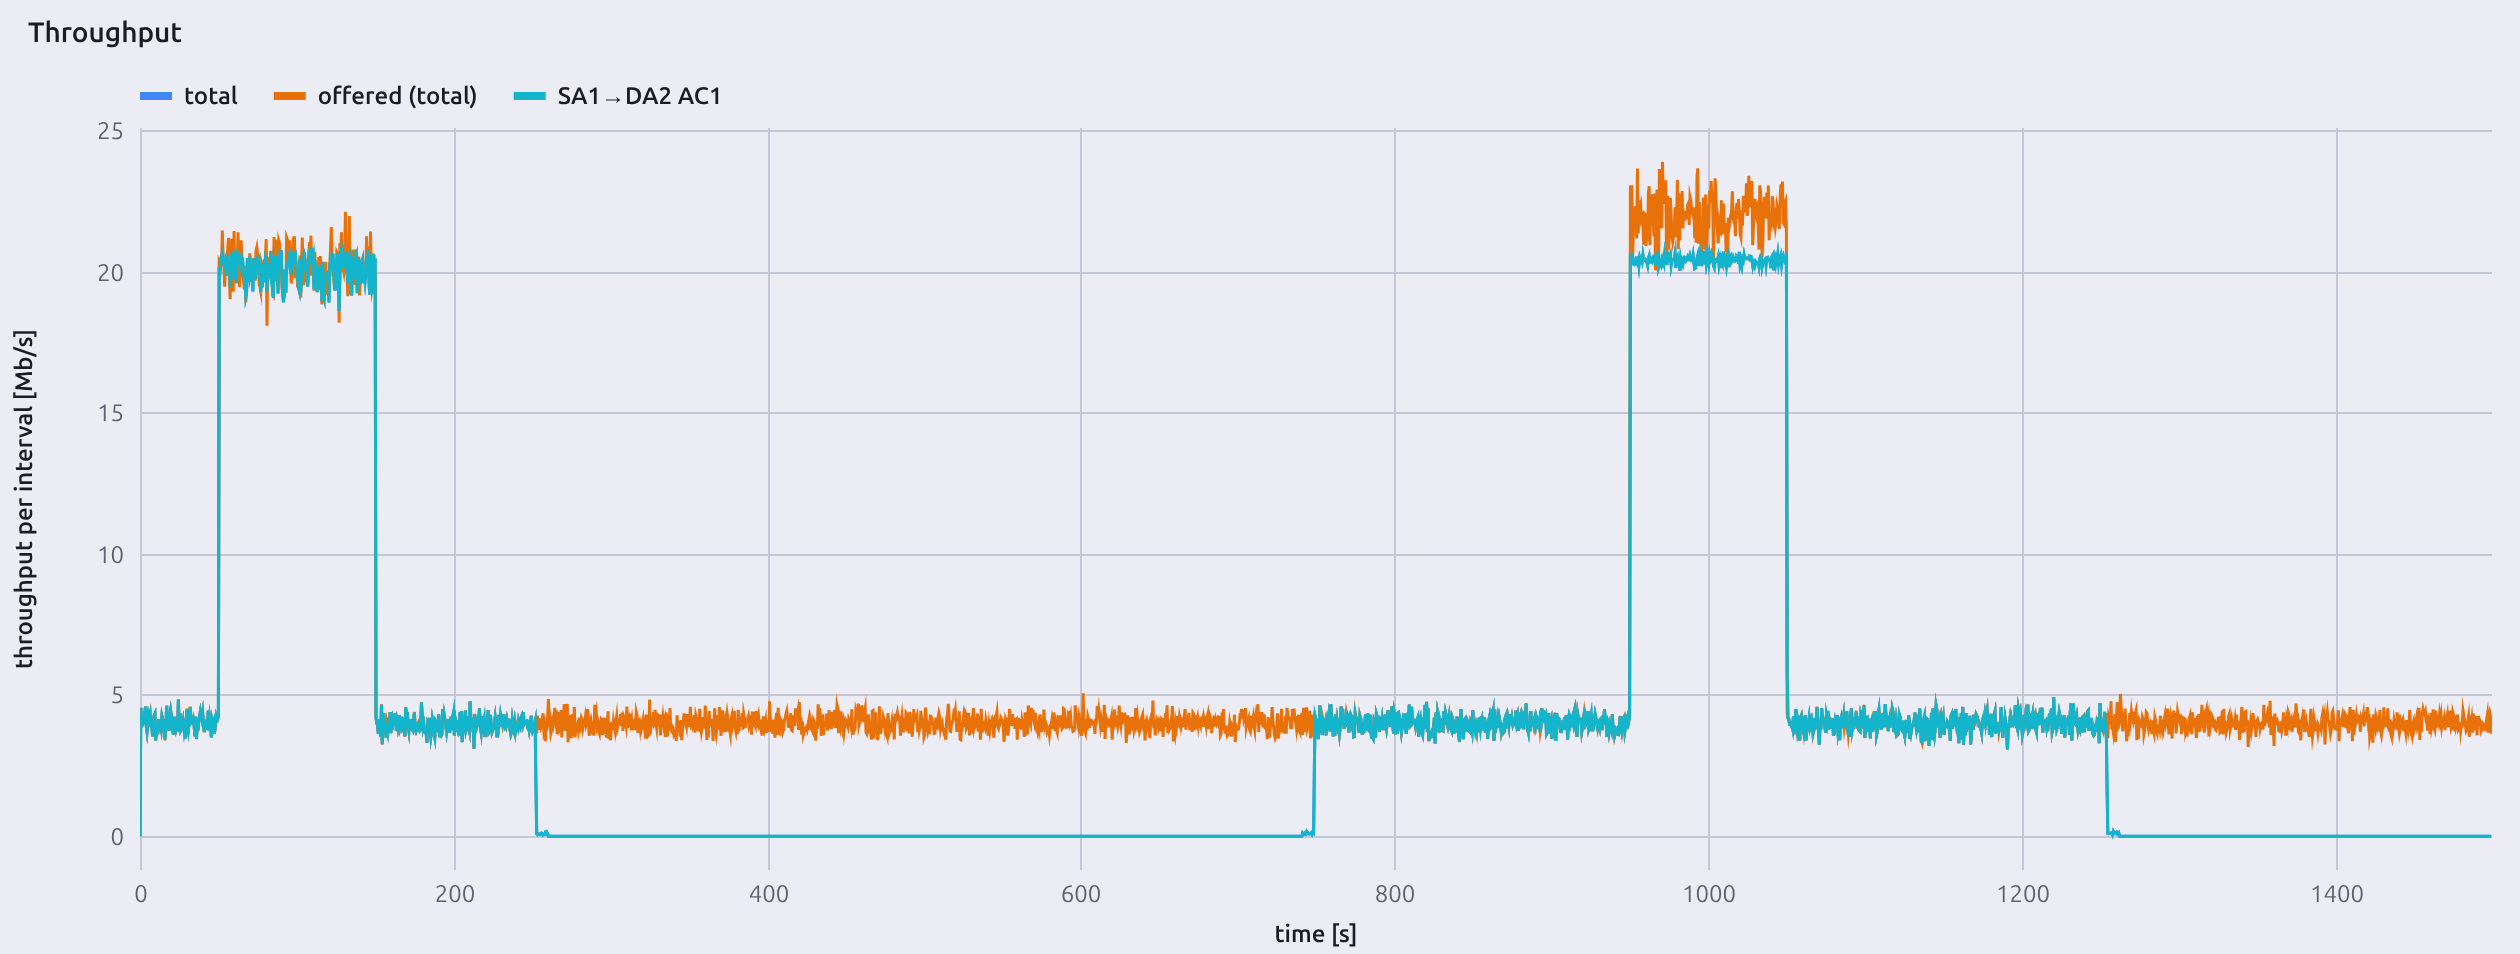

7) At some points, the queue is empty (which is desirable), and other times it is full or even overloaded (at the maximum). Explain why this is the case by looking at the traffic generators (how much Mb/s is offered) and the distance between the two stations. You can also reference the graph from the previous step.

<div class="alert alert-info">

(M) Answer: The generators offer 4 Mb/s normally, 20 Mb/s from 50–150 s, and 22 Mb/s from 950–1050 s. When the stations are close, throughput keeps up and the queue stays nearly empty. As the mobile station moves farther away, weaker reception and retransmissions reduce throughput below the offered load, filling the 100-packet queue and causing drops. The traffic bursts also fill the queue, as seen where offer exceeds throughput in the graph.

### Step 3: PID Algorithm Implementation (6 points)

1) Go back to the custom static algorithm. What PhyModes are available and which is the most reliable?

<div class="alert alert-info">

(S) Answer: The available PHY modes are BPSK12, BPSK34, QPSK12, QPSK34, 16QAM12, 16QAM34, 64QAM23, and 64QAM34. BPSK12 is the most reliable because its robust modulation and 1/2 coding rate tolerate weaker signals, at the cost of the lowest data rate (6 Mb/s).

2) The transmission power should be at most 0 dBm, a realistic number for Wi-Fi IEEE 802.11 systems. Why should you (in real-life and upcoming tasks) set the transmission power dynamically to the minimum value possible?

<div class="alert alert-info">

(S) Answer: Using the minimum power needed for a reliable link saves energy and reduces interference with other devices, allowing better channel reuse. Dynamic adjustment maintains reliability as distance and channel conditions change.

3) Build a PID algorithm using all three PID components. It should dynamically adapt and set two physical properties (limit dBm to 0 and use only the given PhyModes). There are other examples in the same folder, `jemula-project/my-simulations/algorithms/layer2_802Algorithms`: put yours there too, name its class in the scenario's `NameOfAlgorithm`, and [`Jemula802_Run.ipynb`](../../notebooks/01%20Jemula/Jemula802_Run.ipynb) compiles it before every run. Upload the algorithm `.java` file as well. Did you include this file separately in your submission?

<div class="alert alert-info">

(S) Answer: Yes if we did remember.

4) Demonstrate the performance of your algorithm. Provide graphs of offer and throughput, queue size, and the transmission power over time. The plots your algorithm draws (its `plot()`, with `ShowPlot="true"`) appear as tabs in the run's `timeline.html`, where Save PNG saves them. Analyze and evaluate the results.

<div class="alert alert-info">

(V, L) Answer: 
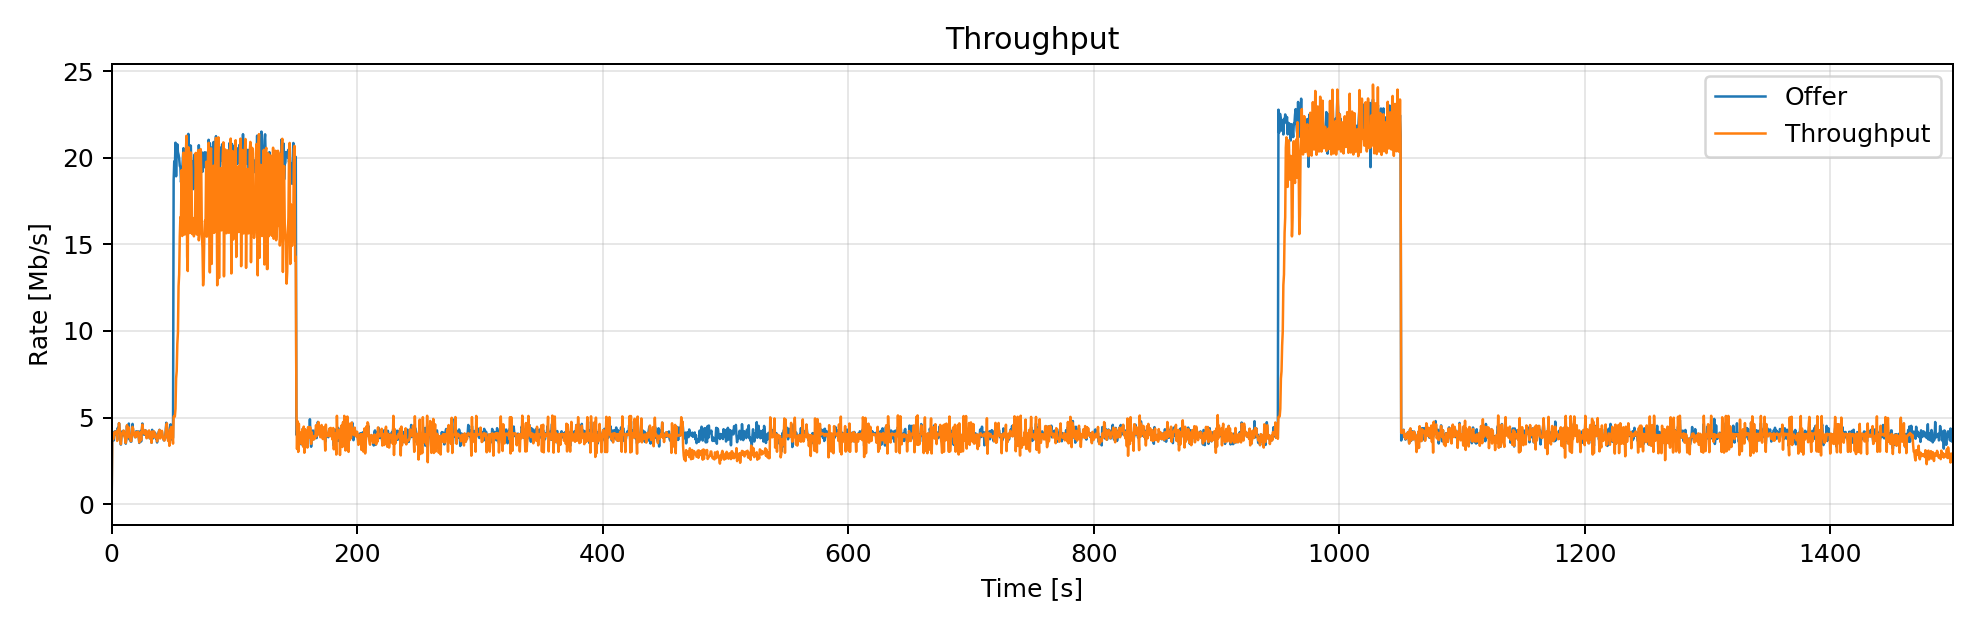
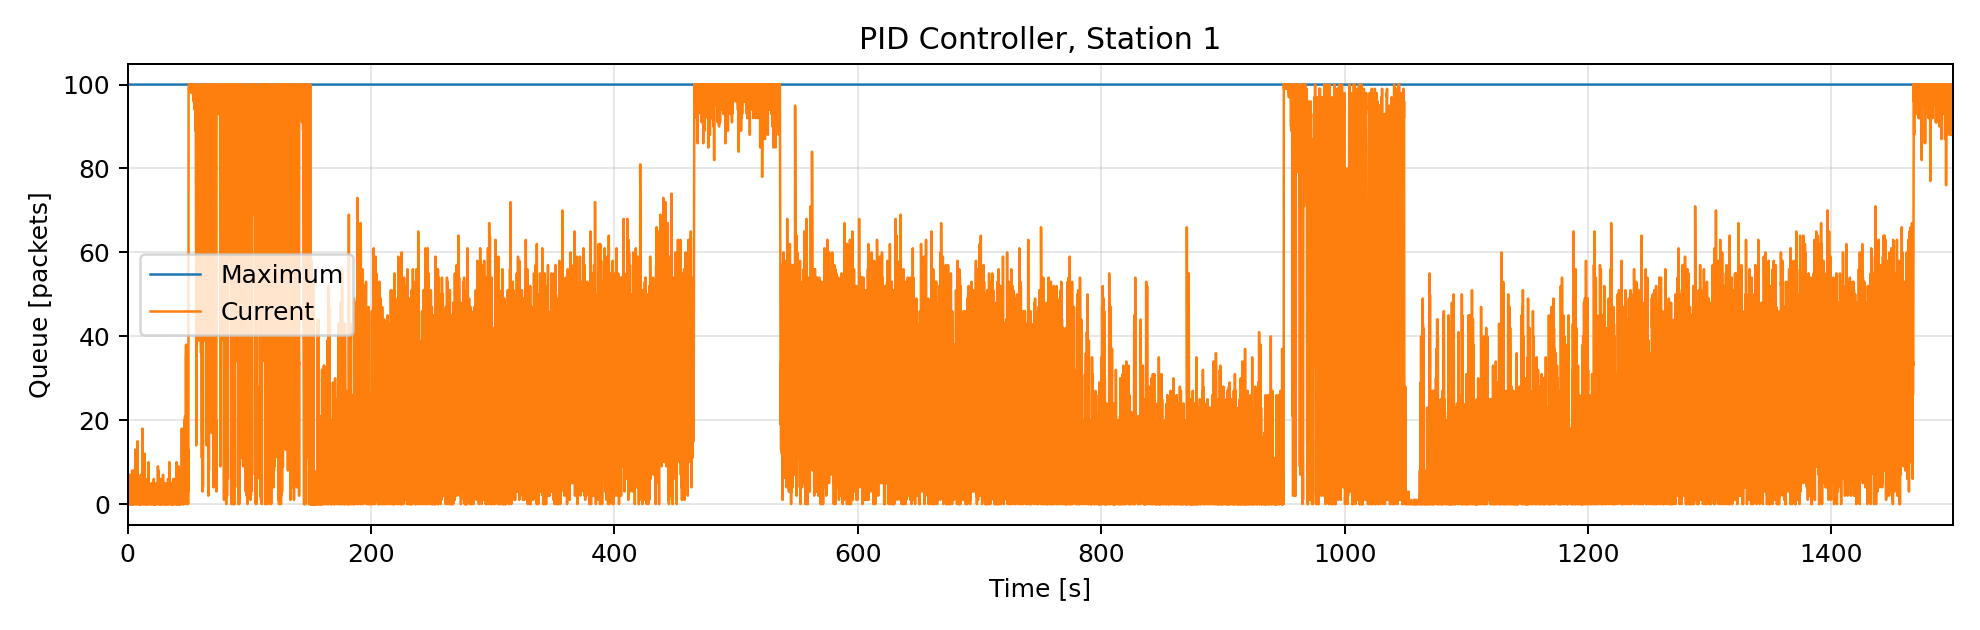
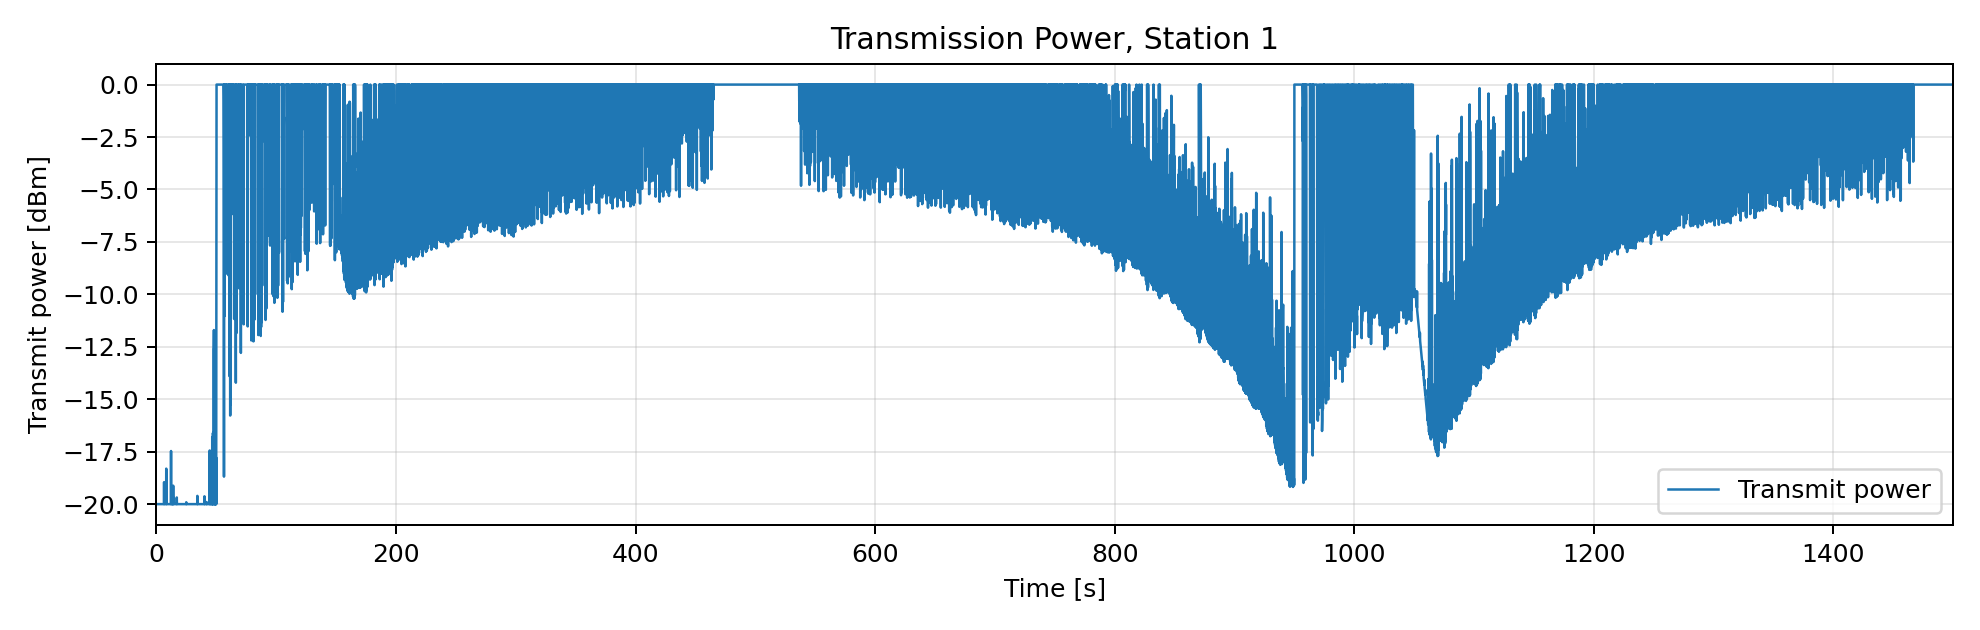

These results use the queue-feedback controller submitted as [WNMC_PID.java](WNMC_PID.java), also saved in [PID_Performance/WNMC_PID.java](PID_Performance/WNMC_PID.java).

The full run delivered 5.84 Mb/s on average against 6.26 Mb/s offered (93.4%), compared with 4.18 Mb/s in the earlier static run. Queue occupancy averaged 31.6 packets, reaching capacity in 3.6% of samples. Power stayed between −20 and 0 dBm, averaging 0.62 mW, approximately 38% below constant 0 dBm. Adaptation improves throughput and reduces transmit power, but queue oscillations and saturation during traffic bursts show that tuning remains necessary.

5) On a high-level, explain how your algorithm operates.

<div class="alert alert-info">

(M) Answer: The algorithm monitors queue occupancy and targets about 10 packets. The proportional term reacts to current congestion, the integral term accounts for persistent congestion, and the derivative term reacts to how quickly it changes. Together, they adjust transmission power between −20 and 0 dBm and guide PHY-mode selection. Failed transmissions trigger a more robust PHY mode, while output limits and anti-windup prevent excessive adjustments.

6) Use `theUniqueEventScheduler.now().getTimeMs()` to get the current time. Instead of reading the actual queue size, input a self-generated Dirac impulse going from 0 to 80 at 1s. Explain how this affects the performance and how your algorithm acts. Provide graphs of offer and throughput, queue size, and the transmission power over time. The plots your algorithm draws (its `plot()`, with `ShowPlot="true"`) appear as tabs in the run's `timeline.html`, where Save PNG saves them.

<div class="alert alert-info">

(V, L) Answer: 
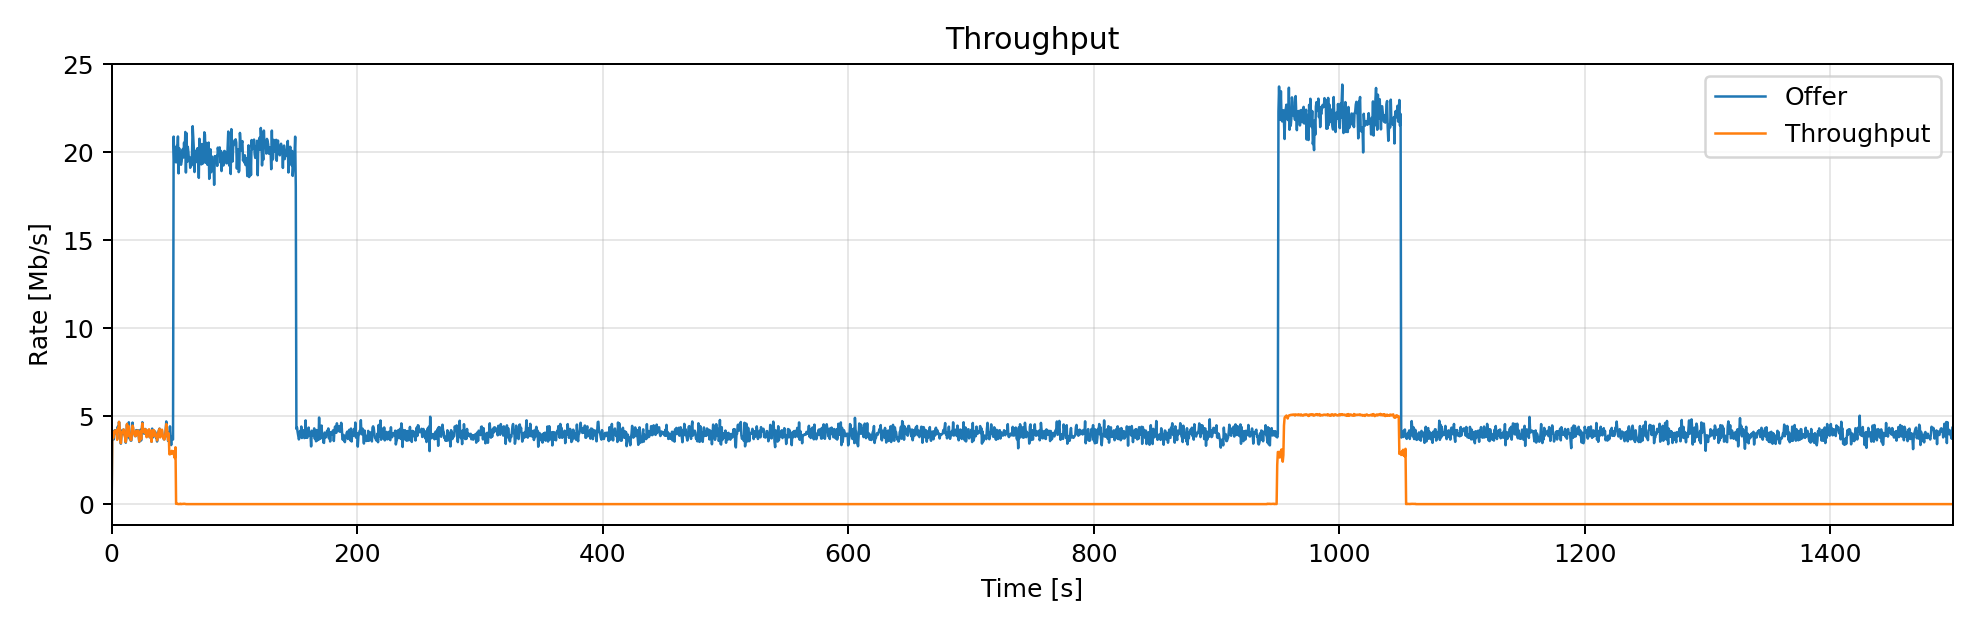
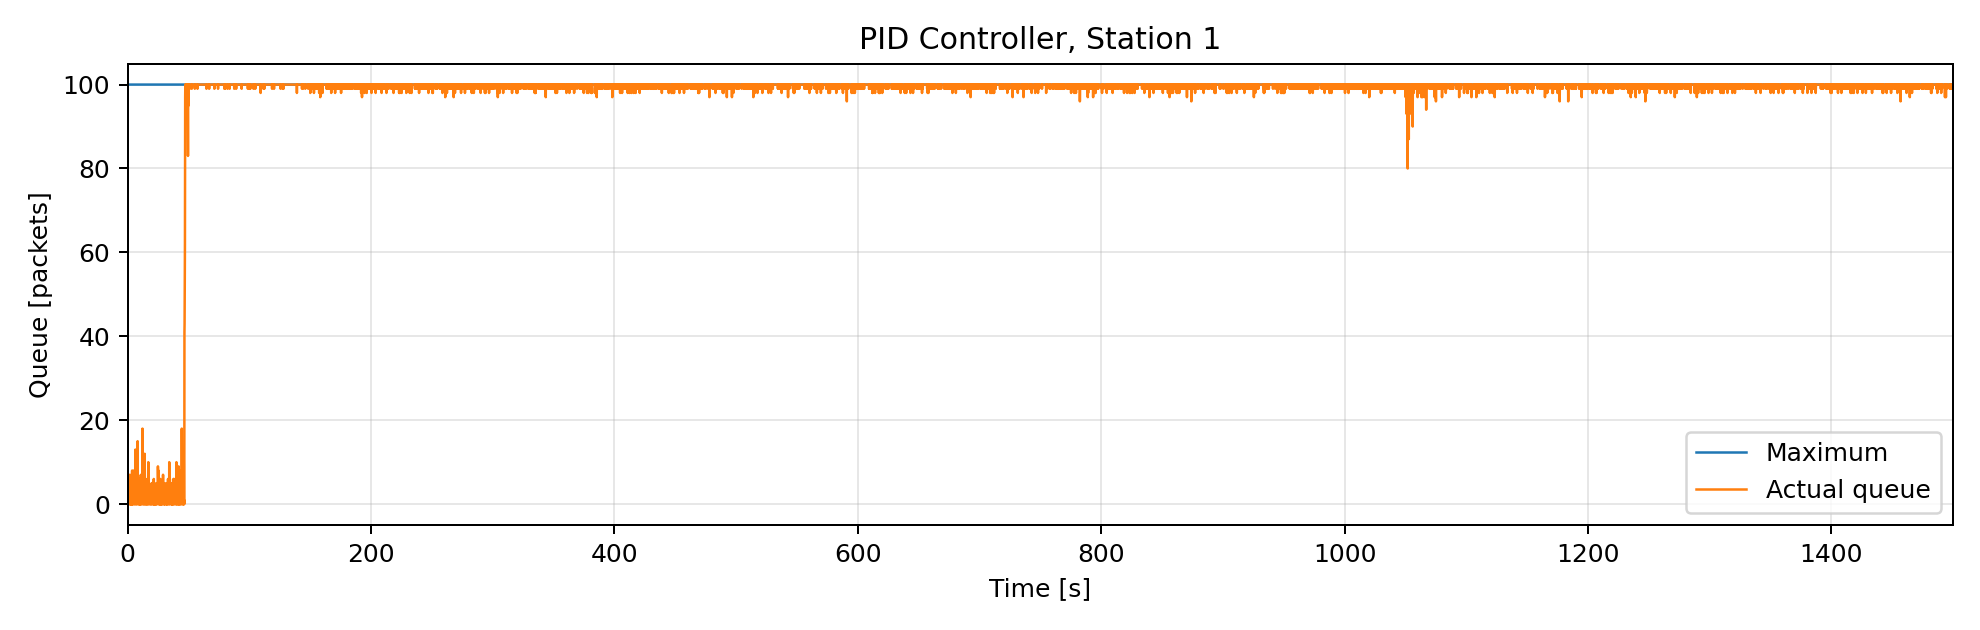
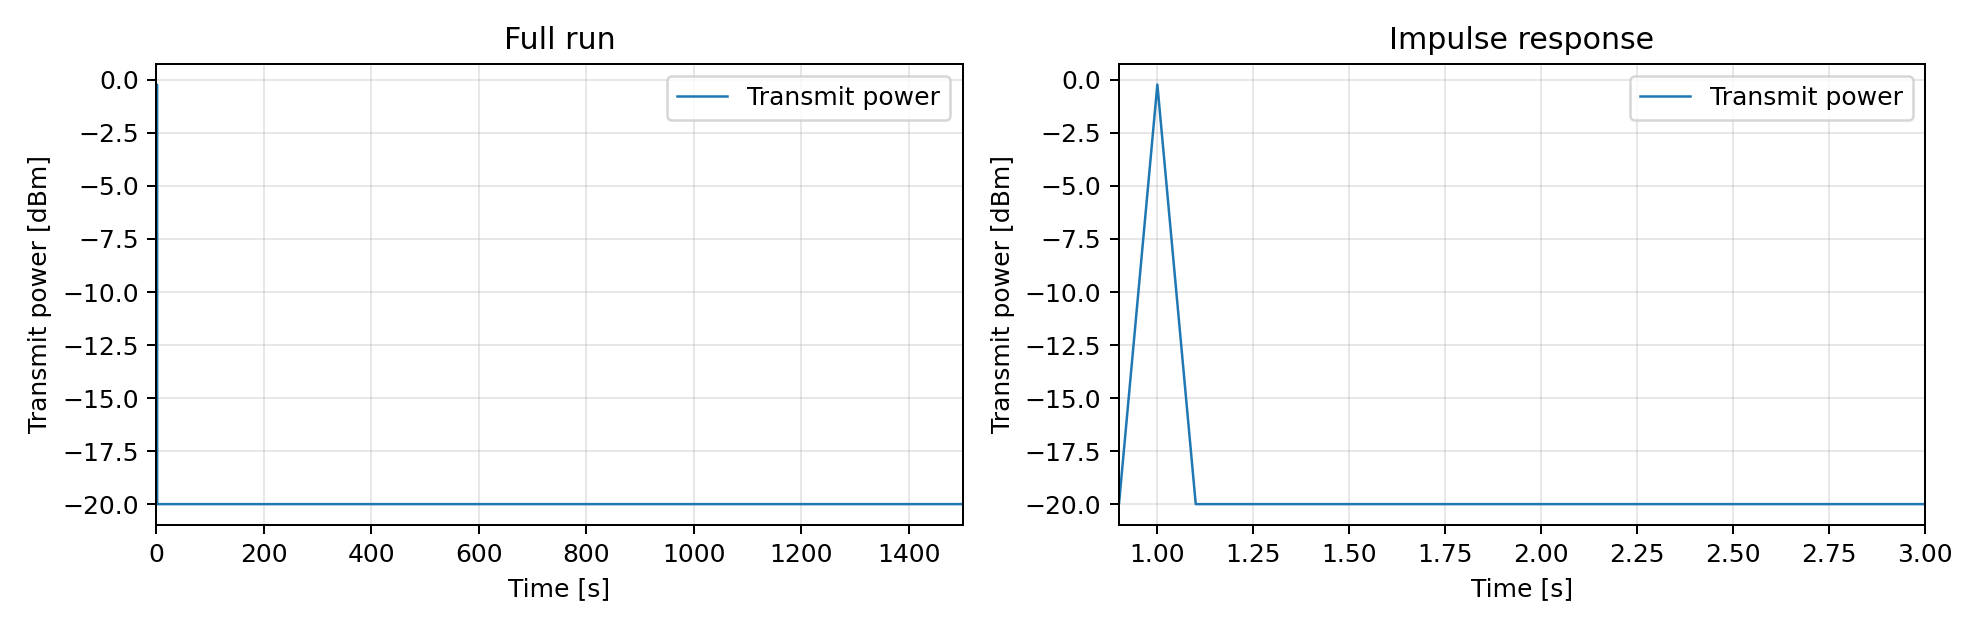

This experiment uses the separate impulse-input controller [WNMC_DiracPID.java](WNMC_DiracPID.java), not the queue-feedback controller described above. To reproduce it, set the station's NameOfAlgorithm to WNMC_DiracPID and recompile. Set it back to WNMC_PID to run the queue-feedback controller.

The synthetic input is 80 at 1 s for one 0.1-second sample, then zero. The PID briefly raises power to −0.22 dBm, before returning to −20 dBm. Without real queue feedback, it cannot react to congestion: throughput averages only 0.47 Mb/s against 6.26 Mb/s offered, and the actual queue is full in 82.3% of samples. This demonstrates the impulse response, but performs poorly as traffic control because the controller is disconnected from actual demand.

### Optional Feedback (not graded)

1. Did you read through and understand all the tasks in this assignment and the related notebooks? Are there any shortcomings, missing parts, or sections that should be improved? You can also give your feedback anonymously, through moodle. Please help the teaching team by telling us what part was not understood, and we will work on it in the future.

<div class="alert alert-info">

Optional Feedback, not graded: *(double click to edit)*